# Enzyme Kinetics: Fitting the Michaelis-Menten Model with SciPy

**Question:** given noisy rate measurements at different substrate concentrations, how well can we recover an enzyme's $V_{max}$ and $K_m$, and what happens if we use the classic linear (Lineweaver-Burk) shortcut instead of a proper nonlinear fit?

**Data note:** all measurements are **simulated** from known true parameters, so we can check how close each method gets. They are not real lab data.

## The model

Michaelis-Menten kinetics:

$$v = \frac{V_{max}\,[S]}{K_m + [S]}$$

- $V_{max}$ is the maximum rate when the enzyme is saturated.
- $K_m$ is the substrate concentration at which $v = V_{max}/2$.

With a **competitive inhibitor** at concentration $[I]$ and inhibition constant $K_i$, the apparent $K_m$ grows:

$$v = \frac{V_{max}\,[S]}{K_m\left(1 + \dfrac{[I]}{K_i}\right) + [S]}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import t

rng = np.random.default_rng(7)

def michaelis_menten(S, Vmax, Km):
    return Vmax * S / (Km + S)

## 1. Simulate noisy measurements

True values: $V_{max} = 100$ µmol/min and $K_m = 2.5$ mM. Eight substrate concentrations, three replicates each, with Gaussian measurement noise (standard deviation 3 µmol/min).

In [2]:
true_Vmax, true_Km = 100.0, 2.5
S_levels = np.array([0.2, 0.5, 1, 2, 4, 8, 16, 32])      # mM
S = np.repeat(S_levels, 3)                                # 3 replicates each
v_obs = michaelis_menten(S, true_Vmax, true_Km) + rng.normal(0, 3.0, size=S.size)

print("n measurements:", S.size)
print("Smallest observed rate: %.2f" % v_obs.min())

n measurements: 24
Smallest observed rate: 6.58


## 2. Nonlinear least-squares fit

`curve_fit` finds the parameters that minimize the sum of squared residuals. We give it starting guesses (`p0`) from the data, then use the covariance matrix to get standard errors and 95% confidence intervals.

In [3]:
popt, pcov = curve_fit(michaelis_menten, S, v_obs, p0=[v_obs.max(), np.median(S)])
perr = np.sqrt(np.diag(pcov))
dof = S.size - len(popt)
t_crit = t.ppf(0.975, dof)

for name, est, se, true in zip(["Vmax", "Km"], popt, perr, [true_Vmax, true_Km]):
    print("%-5s fit = %7.3f  (95%% CI %7.3f to %7.3f)   true = %.3f" %
          (name, est, est - t_crit * se, est + t_crit * se, true))

residuals = v_obs - michaelis_menten(S, *popt)
r_squared = 1 - (residuals ** 2).sum() / ((v_obs - v_obs.mean()) ** 2).sum()
print("R^2 = %.4f" % r_squared)

Vmax  fit =  96.672  (95% CI  94.128 to  99.217)   true = 100.000
Km    fit =   2.393  (95% CI   2.170 to   2.617)   true = 2.500
R^2 = 0.9946


## 3. Compare with the Lineweaver-Burk (double-reciprocal) plot

Taking reciprocals turns the model into a straight line: $\dfrac{1}{v} = \dfrac{K_m}{V_{max}}\dfrac{1}{[S]} + \dfrac{1}{V_{max}}$. It is easy to do by hand, but it distorts the error: small measured rates become huge reciprocals and dominate the fit.

In [4]:
mask = v_obs > 0     # reciprocals need positive rates
print("Points dropped for non-positive rate:", (~mask).sum())

slope, intercept = np.polyfit(1 / S[mask], 1 / v_obs[mask], 1)
Vmax_lb = 1 / intercept
Km_lb = slope * Vmax_lb

print("Lineweaver-Burk: Vmax = %.3f, Km = %.3f" % (Vmax_lb, Km_lb))
print("Nonlinear fit:   Vmax = %.3f, Km = %.3f" % tuple(popt))
print("True:            Vmax = %.3f, Km = %.3f" % (true_Vmax, true_Km))
print("Absolute error in Vmax - nonlinear: %.3f, Lineweaver-Burk: %.3f" %
      (abs(popt[0] - true_Vmax), abs(Vmax_lb - true_Vmax)))
print("Absolute error in Km   - nonlinear: %.3f, Lineweaver-Burk: %.3f" %
      (abs(popt[1] - true_Km), abs(Km_lb - true_Km)))
print("One dataset can mislead. The next section repeats the experiment many times.")

Points dropped for non-positive rate: 0
Lineweaver-Burk: Vmax = 92.576, Km = 2.362
Nonlinear fit:   Vmax = 96.672, Km = 2.393
True:            Vmax = 100.000, Km = 2.500
Absolute error in Vmax - nonlinear: 3.328, Lineweaver-Burk: 7.424
Absolute error in Km   - nonlinear: 0.107, Lineweaver-Burk: 0.138
One dataset can mislead. The next section repeats the experiment many times.


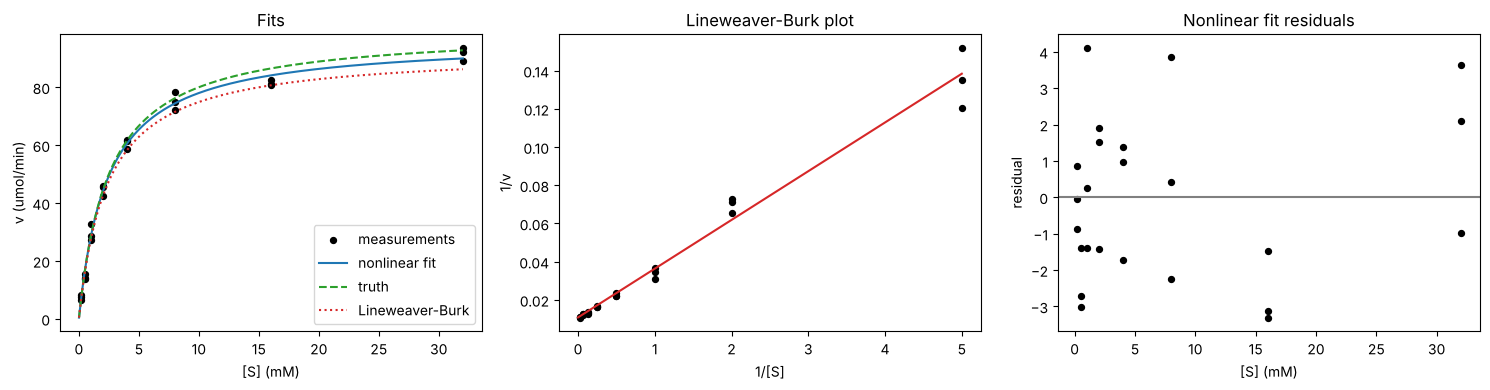

In [5]:
S_curve = np.linspace(0.01, S.max(), 300)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(S, v_obs, color="k", s=18, label="measurements")
axes[0].plot(S_curve, michaelis_menten(S_curve, *popt), color="tab:blue", label="nonlinear fit")
axes[0].plot(S_curve, michaelis_menten(S_curve, true_Vmax, true_Km), "--", color="tab:green", label="truth")
axes[0].plot(S_curve, michaelis_menten(S_curve, Vmax_lb, Km_lb), ":", color="tab:red", label="Lineweaver-Burk")
axes[0].set_xlabel("[S] (mM)"); axes[0].set_ylabel("v (umol/min)"); axes[0].set_title("Fits"); axes[0].legend()

axes[1].scatter(1 / S[mask], 1 / v_obs[mask], color="k", s=18)
x_line = np.linspace(0, (1 / S[mask]).max(), 100)
axes[1].plot(x_line, slope * x_line + intercept, color="tab:red")
axes[1].set_xlabel("1/[S]"); axes[1].set_ylabel("1/v"); axes[1].set_title("Lineweaver-Burk plot")

axes[2].scatter(S, residuals, color="k", s=18)
axes[2].axhline(0, color="gray")
axes[2].set_xlabel("[S] (mM)"); axes[2].set_ylabel("residual"); axes[2].set_title("Nonlinear fit residuals")

plt.tight_layout()
plt.show()

## 3b. Repeat the experiment 500 times

A single simulated dataset can favour either method by luck. Here we repeat the whole experiment 500 times with fresh noise and compare the root-mean-square error (RMSE) of each method's estimates against the known truth. A separate random generator is used so earlier results do not change.

In [6]:
rng_mc = np.random.default_rng(123)
n_sims = 500
err = {"nl_Vmax": [], "nl_Km": [], "lb_Vmax": [], "lb_Km": []}
failed = 0

for _ in range(n_sims):
    v = michaelis_menten(S, true_Vmax, true_Km) + rng_mc.normal(0, 3.0, size=S.size)
    try:
        p, _ = curve_fit(michaelis_menten, S, v, p0=[v.max(), np.median(S)])
    except RuntimeError:
        failed += 1
        continue
    keep = v > 0
    sl, ic = np.polyfit(1 / S[keep], 1 / v[keep], 1)
    lb_V = 1 / ic
    lb_K = sl * lb_V
    err["nl_Vmax"].append(p[0] - true_Vmax); err["nl_Km"].append(p[1] - true_Km)
    err["lb_Vmax"].append(lb_V - true_Vmax); err["lb_Km"].append(lb_K - true_Km)

rmse = {k: np.sqrt(np.mean(np.square(v_))) for k, v_ in err.items()}
medabs = {k: np.median(np.abs(v_)) for k, v_ in err.items()}
bias = {k: np.mean(v_) for k, v_ in err.items()}
worst = {k: np.max(np.abs(v_)) for k, v_ in err.items()}
print("Simulations completed: %d (nonlinear fit failed to converge in %d)" % (len(err["nl_Km"]), failed))
print("%-10s %12s %14s %12s %12s" % ("", "RMSE", "median |err|", "mean error", "worst |err|"))
for k in ["nl_Vmax", "lb_Vmax", "nl_Km", "lb_Km"]:
    print("%-10s %12.3f %14.3f %12.3f %12.3f" % (k, rmse[k], medabs[k], bias[k], worst[k]))

Simulations completed: 500 (nonlinear fit failed to converge in 0)
                   RMSE   median |err|   mean error  worst |err|
nl_Vmax           1.597          1.165        0.048        5.311
lb_Vmax        1592.447         23.542       85.214    34328.186
nl_Km             0.139          0.095        0.006        0.392
lb_Km            72.115          1.067        3.921     1551.333


Read the table: `nl_` is the nonlinear fit, `lb_` is Lineweaver-Burk.

- **Median |error|** shows the typical case. **RMSE** and **worst |error|** are dominated by rare failures, because when the Lineweaver-Burk intercept lands near zero, $V_{max} = 1/\text{intercept}$ blows up.
- A mean error far from zero means a method is biased.

Compare the typical-case and the worst-case columns, then write one or two sentences in your own words about what you see and why both matter when choosing a fitting method.

## 4. Competitive inhibition: a global fit

Now we measure at three inhibitor concentrations and fit all the data at once to recover $V_{max}$, $K_m$ and $K_i$ together. True $K_i$ = 3.0 mM.

In [7]:
def competitive(X, Vmax, Km, Ki):
    S, I = X
    return Vmax * S / (Km * (1 + I / Ki) + S)

true_Ki = 3.0
I_levels = np.array([0.0, 2.0, 5.0])        # mM
S_all = np.tile(np.repeat(S_levels, 3), len(I_levels))
I_all = np.repeat(I_levels, S_levels.size * 3)
v_inh = competitive((S_all, I_all), true_Vmax, true_Km, true_Ki) + rng.normal(0, 3.0, size=S_all.size)

popt_i, pcov_i = curve_fit(competitive, (S_all, I_all), v_inh, p0=[100, 2, 2])
perr_i = np.sqrt(np.diag(pcov_i))
dof_i = S_all.size - len(popt_i)
t_i = t.ppf(0.975, dof_i)

for name, est, se, true in zip(["Vmax", "Km", "Ki"], popt_i, perr_i, [true_Vmax, true_Km, true_Ki]):
    print("%-5s fit = %7.3f  (95%% CI %7.3f to %7.3f)   true = %.3f" %
          (name, est, est - t_i * se, est + t_i * se, true))

Vmax  fit = 100.108  (95% CI  98.082 to 102.133)   true = 100.000
Km    fit =   2.609  (95% CI   2.399 to   2.820)   true = 2.500
Ki    fit =   3.291  (95% CI   2.821 to   3.761)   true = 3.000


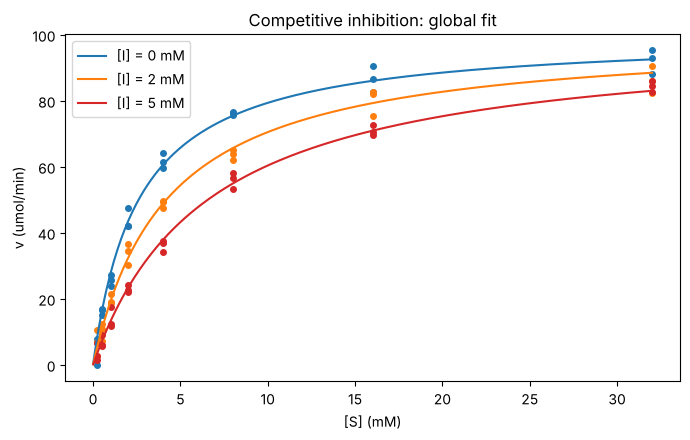

In [8]:
plt.figure(figsize=(7, 4.5))
for I_val, color in zip(I_levels, ["tab:blue", "tab:orange", "tab:red"]):
    sel = I_all == I_val
    plt.scatter(S_all[sel], v_inh[sel], s=16, color=color)
    plt.plot(S_curve, competitive((S_curve, np.full_like(S_curve, I_val)), *popt_i),
             color=color, label="[I] = %.0f mM" % I_val)
plt.xlabel("[S] (mM)"); plt.ylabel("v (umol/min)")
plt.title("Competitive inhibition: global fit")
plt.legend()
plt.tight_layout()
plt.show()

## Check your understanding

1. Why does the standard error from `curve_fit` shrink if you add more replicates?
2. Why does Lineweaver-Burk give less reliable estimates than the nonlinear fit? (Hint: think about what happens to the noise when you take $1/v$ at low substrate.)
3. In the inhibition plot, what happens to $V_{max}$ and the apparent $K_m$ as [I] increases for a competitive inhibitor?
4. If your fit's confidence interval for $K_i$ were very wide, what experiment would you change?

## Limitations

- The noise here is constant-variance Gaussian. Real assays often have noise that grows with the rate, which calls for weighted fitting.
- Real data needs checks for substrate depletion, enzyme instability and the initial-rate assumption.
- Simulated data shows the fitting method works on a clean case. It is not a measurement of any real enzyme.